**Unit 2 Q1: Particle in a box (finite difference method)**

n    Numerical (eV)    Analytical (eV)
1     1.5037          1.5037
2     6.0147          6.0148
3     13.533          13.5334


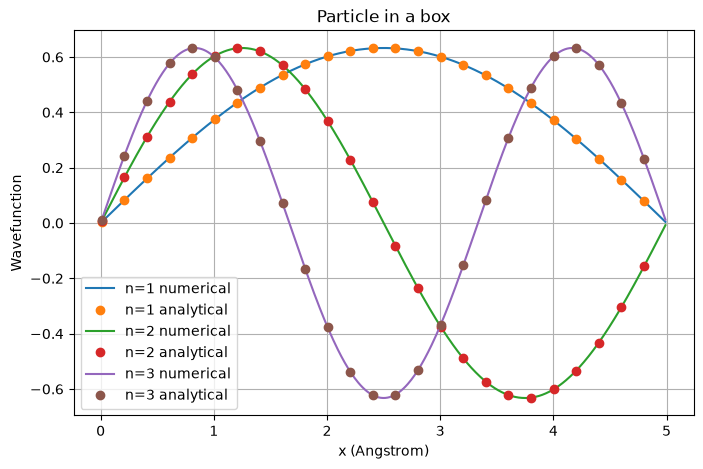

In [2]:
import numpy as np
import matplotlib.pyplot as plt

hc = 1973.0
mc2 = 0.511e6
c = hc ** 2 / (2 * mc2)

L = 5.0
N = 500
x = np.linspace(0, L, N + 2)
dx = x[1] - x[0]
x = x[1:-1]

H = np.diag(2 * c / dx ** 2 * np.ones(N))
H = H + np.diag(-c / dx ** 2 * np.ones(N - 1), 1)
H = H + np.diag(-c / dx ** 2 * np.ones(N - 1), -1)

E, psi = np.linalg.eigh(H)

print("n    Numerical (eV)    Analytical (eV)")
for n in range(1, 4):
    E_exact = n ** 2 * np.pi ** 2 * c / L ** 2
    print(n, "   ", round(E[n - 1], 4), "        ", round(E_exact, 4))

plt.figure(figsize=(8, 5))
for n in range(1, 4):
    numerical = psi[:, n - 1] / np.sqrt(np.sum(psi[:, n - 1] ** 2) * dx)
    exact = np.sqrt(2 / L) * np.sin(n * np.pi * x / L)
    if np.sum(numerical * exact) < 0:
        numerical = -numerical
    plt.plot(x, numerical, label=f"n={n} numerical")
    plt.plot(x[::20], exact[::20], "o", label=f"n={n} analytical")

plt.xlabel("x (Angstrom)")
plt.ylabel("Wavefunction")
plt.title("Particle in a box")
plt.legend()
plt.grid(True)
plt.show()
